# 4. Real data: the Hillstrom e-mail experiment

Notebooks 1-3 use a simulator so that every method can be checked against the truth. Here I apply the same tools to real randomized data, where there's no answer key and the data is sparse and noisy.

The data is Kevin Hillstrom's public MineThatData E-Mail Analytics challenge (2008). 64,000 customers who had bought something in the previous 12 months were randomly assigned to a Men's merchandise e-mail, a Women's merchandise e-mail or no e-mail, and tracked for two weeks: `visit`, `conversion` (purchase) and `spend`. Pre-experiment variables: `recency`, `history` (spend in the past year), `mens` / `womens` (bought that category), `newbie`, `zip_code`, `channel`.

The business question: should we send the e-mail, which one, and to whom?

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chisquare
from statsmodels.stats.multitest import multipletests
from IPython.display import display

from src import analysis as an, power, uplift as up

from src.plotting import use_style, SURFACE, INK, INK2, MUTED, GRID, AXIS, BLUE, ORANGE
use_style()
pd.options.display.float_format = "{:,.4f}".format

h = pd.read_csv("../data/raw/hillstrom_email.csv")
h["zip_code"] = h.zip_code.replace({"Surburban": "Suburban"})            # typo in the source file
h["arm"] = h.segment.map({"No E-Mail": 0, "Mens E-Mail": 1, "Womens E-Mail": 2})
h["hist_band"] = pd.cut(h.history, [0, 100, 350, np.inf], labels=["<$100", "$100-350", "$350+"])
print(h.shape); h.head()

(64000, 14)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,arm,hist_band
0,10,2) $100 - $200,142.4400,1,0,Suburban,0,Phone,Womens E-Mail,0,0,0.0000,2,$100-350
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000,0,$100-350
2,7,2) $100 - $200,180.6500,0,1,Suburban,1,Web,Womens E-Mail,0,0,0.0000,2,$100-350
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000,1,$350+
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000,2,<$100


## 1. Data audit

First a look at the shape of the outcome, since it affects which test makes sense.

In [2]:
print("Missing values:", int(h.isna().sum().sum()))
print(f"Customers with spend > 0 : {(h.spend > 0).mean():.2%}  (conversion rate {h.conversion.mean():.2%}; spend>0 iff conversion: {((h.spend > 0) == (h.conversion == 1)).all()})")
print(f"Spend: mean {h.spend.mean():.2f}, sd {h.spend.std():.2f}  (sd/mean = {h.spend.std() / h.spend.mean():.0f}),  max {h.spend.max():.0f}")
print(f"Spend among buyers: mean {h.loc[h.conversion == 1, 'spend'].mean():.1f}, sd {h.loc[h.conversion == 1, 'spend'].std():.1f}")
print(f"Visit rate {h.visit.mean():.1%}")

Missing values: 0
Customers with spend > 0 : 0.90%  (conversion rate 0.90%; spend>0 iff conversion: True)
Spend: mean 1.05, sd 15.04  (sd/mean = 14),  max 499
Spend among buyers: mean 116.4, sd 107.9
Visit rate 14.7%


99% of customers spend nothing and the rest spend ~\$116 on average. So the metric is a rare event times a widely spread amount, with a standard deviation 14x its mean. That's a lot noisier than the simulated app (sd/mean ~6), and it affects everything below.

## 2. Validity checks

A three-arm SRM test (chi-square against an equal split) and covariate balance (standardized mean difference of each pre-experiment variable, each e-mail arm against control).

In [3]:
counts = h.arm.value_counts().sort_index()
print("Arm sizes (control, men's, women's):", counts.tolist(), f"-> SRM p-value = {an.srm_check_multi(counts.to_numpy()):.3f}")

dummies = pd.get_dummies(h[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=float)
bal = {}
for arm, name in [(1, "Men's vs control"), (2, "Women's vs control")]:
    d = (h.arm == arm) | (h.arm == 0); t = (h.arm[d] == arm).to_numpy().astype(int)
    bal[name] = {c: an.standardized_mean_diff(dummies.loc[d, c].to_numpy(), t) for c in dummies}
bal = pd.DataFrame(bal)
print(f"\nLargest |SMD| across {len(bal)} variables: {bal.abs().max().max():.3f}  (bar: 0.1)")
display(bal.abs().max().to_frame("max |SMD|").T)

Arm sizes (control, men's, women's): [21306, 21307, 21387] -> SRM p-value = 0.904

Largest |SMD| across 11 variables: 0.014  (bar: 0.1)


,Men's vs control,Women's vs control
max |SMD|,0.0137,0.0086


The split is clean (p ~ 0.9) and all covariates are balanced, so the randomization looks fine.

## 3. Main results

The primary metric is spend per customer, since revenue is what matters to the business; visits and conversion are secondary. For spend I also compute a bootstrap interval because of the heavy tail. The three pairwise comparisons on spend are one family of tests, so their p-values get a Holm correction.

In [4]:
def compare(a, b, metric):
    """Effect of arm `a` relative to arm `b` (arm codes), difference in means."""
    d = h[h.arm.isin([a, b])]
    return an.diff_in_means(d[metric].to_numpy().astype(float), (d.arm == a).to_numpy().astype(int)), d

pairs = [("Men's e-mail vs none", 1, 0), ("Women's e-mail vs none", 2, 0), ("Men's vs Women's e-mail", 1, 2)]
rows = []
for label, a, b in pairs:
    for metric in ["spend", "conversion", "visit"]:
        e, d = compare(a, b, metric)
        rows.append({"comparison": label, "metric": metric, "estimate": e.estimate, "ci_low": e.ci_low, "ci_high": e.ci_high, "p_value": e.p_value})
res = pd.DataFrame(rows)
sp = res.metric == "spend"
res.loc[sp, "p_holm (spend family)"] = multipletests(res.loc[sp, "p_value"], method="holm")[1]
display(res.set_index(["comparison", "metric"]))

for label, a, b in pairs:
    e, d = compare(a, b, "spend")
    lo, hi = an.bootstrap_diff(d.spend.to_numpy(), (d.arm == a).to_numpy().astype(int), n_boot=1000, seed=1)
    print(f"Bootstrap 95% CI for spend, {label}: [{lo:+.3f}, {hi:+.3f}]   (normal approx [{e.ci_low:+.3f}, {e.ci_high:+.3f}])")

estimate  ci_low  ci_high  p_value  \
comparison              metric                                           
Men's e-mail vs none    spend         0.7698  0.4851   1.0545   0.0000   
                        conversion    0.0068  0.0050   0.0086   0.0000   
                        visit         0.0766  0.0700   0.0832   0.0000   
Women's e-mail vs none  spend         0.4244  0.1690   0.6799   0.0011   
                        conversion    0.0031  0.0015   0.0047   0.0002   
                        visit         0.0452  0.0389   0.0516   0.0000   
Men's vs Women's e-mail spend         0.3454  0.0326   0.6583   0.0305   
                        conversion    0.0037  0.0017   0.0056   0.0002   
                        visit         0.0314  0.0243   0.0384   0.0000   

                                    p_holm (spend family)  
comparison              metric                             
Men's e-mail vs none    spend                      0.0000  
                        conversion                    NaN  
                        visit                         NaN  
Women's e-mail vs none  spend                      0.0023  
                        conversion                    NaN  
                        visit                         NaN  
Men's vs Women's e-mail spend                      0.0305  
                        conversion                    NaN  
                        visit                         NaN

Bootstrap 95% CI for spend, Men's e-mail vs none: [+0.514, +1.051]   (normal approx [+0.485, +1.055])
Bootstrap 95% CI for spend, Women's e-mail vs none: [+0.146, +0.696]   (normal approx [+0.169, +0.680])


Bootstrap 95% CI for spend, Men's vs Women's e-mail: [+0.032, +0.634]   (normal approx [+0.033, +0.658])


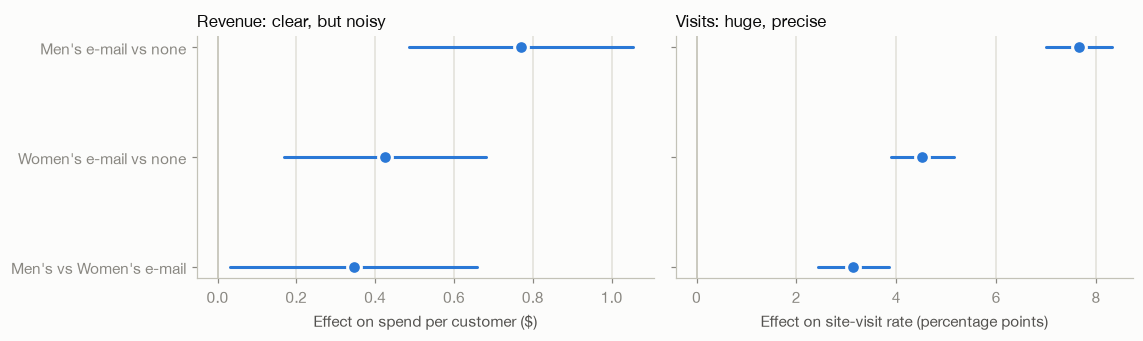

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2), sharey=True)
labels = [p[0] for p in pairs]; ypos = np.arange(len(labels))[::-1]
for ax, metric, scale, xl in [(axes[0], "spend", 1, "Effect on spend per customer ($)"), (axes[1], "visit", 100, "Effect on site-visit rate (percentage points)")]:
    r = res[res.metric == metric].reset_index(drop=True)
    ax.axvline(0, color=AXIS, lw=1)
    for yp, (_, row) in zip(ypos, r.iterrows()):
        ax.plot([row.ci_low * scale, row.ci_high * scale], [yp, yp], color=BLUE, lw=2, solid_capstyle="round")
    ax.plot(r.estimate * scale, ypos, "o", color=BLUE, ms=9, mec=SURFACE, mew=2)
    ax.set_yticks(ypos, labels); ax.grid(axis="y", visible=False); ax.set_xlabel(xl)
axes[0].set_title("Revenue: clear, but noisy", loc="left", fontsize=11, color=INK)
axes[1].set_title("Visits: huge, precise", loc="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig("../reports/figures/04_primary_effects.png", dpi=160); plt.show()

In [6]:
# Where does the lift come from? Descriptive decomposition: conversion rate x average order value (buyers only).
arm_names = {0: "No e-mail", 1: "Men's e-mail", 2: "Women's e-mail"}
dec = h.groupby("arm").apply(lambda g: pd.Series({"customers": len(g), "buyers": int(g.conversion.sum()), "conversion rate": g.conversion.mean(),
                                                  "avg order value (buyers)": g.loc[g.conversion == 1, "spend"].mean(), "spend per customer": g.spend.mean()}), include_groups=False)
dec.index = dec.index.map(arm_names); display(dec)

,customers,buyers,conversion rate,avg order value (buyers),spend per customer
arm,,,,,
No e-mail,"21,306.0000",122.0000,0.0057,114.0027,0.6528
Men's e-mail,"21,307.0000",267.0000,0.0125,113.5269,1.4226
Women's e-mail,"21,387.0000",189.0000,0.0088,121.8948,1.0772


- Both e-mails increase spend: the Men's e-mail by ~\$0.77 per customer (~120% above the \$0.65 control baseline) and the Women's by ~\$0.42. Both survive the Holm correction, and the Men's e-mail beats the Women's by ~\$0.35 (p ~ 0.03, still significant after adjustment).
- The revenue effect is clear statistically but imprecise. The interval for the Men's e-mail goes from about \$0.5 to \$1.05, so the true effect could be half the point estimate or quite a bit above it. Bootstrap and normal intervals agree.
- Visits react a lot and very precisely (+7.7 pp and +4.5 pp, z of ~22 and ~14). Visits are a more sensitive metric than revenue, but a visit isn't a sale, so I only use them as supporting evidence.
- The extra revenue comes from more buyers, while baskets stay about the same size: conversion goes from 0.57% to 1.25% (Men's) and 0.88% (Women's), and the average order value is about \$114-122 in all three arms. (This breakdown conditions on buying, so it's descriptive only.)

## 4. Power, and why CUPED doesn't help here

How small an effect could this test detect, and does pre-experiment information reduce the noise like it did in the simulation?

In [7]:
c = h[h.arm == 0]; n_arm = int(len(h) / 3); sd = c.spend.std()
print(f"MDE for spend with {n_arm:,} per arm (alpha 5%, power 80%): ${power.mde_mean(sd, n_arm):.2f}  -> {power.mde_mean(sd, n_arm) / c.spend.mean():.0%} of the control mean ${c.spend.mean():.2f}")
e_m4, _ = compare(1, 0, "spend"); e_w4, _ = compare(2, 0, "spend")
print(f"Observed lifts: Men's ${e_m4.estimate:.2f}, Women's ${e_w4.estimate:.2f}  (the Women's lift is only about 1.4x the MDE)")

d = h[h.arm.isin([0, 1])]; tt = (d.arm == 1).to_numpy().astype(int)
for name, cov in [("history", d.history.to_numpy()), ("log(history)", np.log(d.history.to_numpy()))]:
    e, vr = an.cuped_effect(d.spend.to_numpy(), cov, tt)
    print(f"CUPED with {name:13s}: corr = {np.corrcoef(cov, d.spend)[0, 1]:+.3f}, variance reduction = {vr:.2%}")
X = dummies.to_numpy(); ols = smf.ols("spend ~ recency + np.log(history) + mens + womens + newbie + C(zip_code) + C(channel)", data=c).fit()
print(f"Regression of spend on ALL pre-experiment covariates (control arm): R^2 = {ols.rsquared:.4f}")

MDE for spend with 21,333 per arm (alpha 5%, power 80%): $0.31  -> 48% of the control mean $0.65
Observed lifts: Men's $0.77, Women's $0.42  (the Women's lift is only about 1.4x the MDE)
CUPED with history      : corr = +0.021, variance reduction = 0.04%
CUPED with log(history) : corr = +0.018, variance reduction = 0.03%


Regression of spend on ALL pre-experiment covariates (control arm): R^2 = 0.0013


Past-year spend, recency and the other covariates explain almost nothing about whether someone buys in the next two weeks (R² ~ 0.13%), so CUPED removes ~0.04% of the variance, i.e. nothing. CUPED only works when the pre-period metric predicts the outcome. In the simulated app last month's in-app spend did, giving a ~19% reduction; for a rare, lumpy purchase like this one it doesn't.

What's left is more customers, a longer window, or a more sensitive but less direct metric. Before using a surrogate like visits to make decisions, you'd have to show that it predicts revenue.

## 5. In money

An effect only matters in money, after costs. The data has no costs or margins, so instead of making up a number I show how the conclusion depends on those two unknowns.

In [8]:
e_m, _ = compare(1, 0, "spend"); e_w, _ = compare(2, 0, "spend")
rows = []
for label, e in [("Men's e-mail", e_m), ("Women's e-mail", e_w)]:
    rows.append({"campaign": label, "extra revenue per 1,000 customers ($)": e.estimate * 1000,
                 "95% CI low": e.ci_low * 1000, "95% CI high": e.ci_high * 1000,
                 "break-even cost per e-mail @ 100% margin": e.estimate, "@ 40% margin": 0.4 * e.estimate, "@ 40% margin, CI low": 0.4 * e.ci_low})
display(pd.DataFrame(rows).set_index("campaign").style.format("{:,.2f}"))

,"extra revenue per 1,000 customers ($)",95% CI low,95% CI high,break-even cost per e-mail @ 100% margin,@ 40% margin,"@ 40% margin, CI low"
campaign,,,,,,
Men's e-mail,769.83,485.15,"1,054.51",0.77,0.31,0.19
Women's e-mail,424.41,168.96,679.86,0.42,0.17,0.07


Sending the Men's e-mail to 1,000 customers brings ~\$770 of extra revenue (CI ~\$490-1,050). The e-mail is worth sending as long as it costs less than margin × \$0.77 per customer. Even with a 40% margin and the pessimistic end of the interval that's about 20 cents per customer, far above what sending an e-mail typically costs (a small fraction of a cent to a few cents). What's measured is revenue, not profit, and unsubscribes or fatigue fall outside the two-week window.

## 6. Does the effect differ across customers?

(a) A hypothesis decided in advance, "interest match": the Men's e-mail should work better for customers who bought men's items before (`mens = 1`), and the same for the Women's e-mail and `womens = 1`. I test it with an interaction term and robust (HC3) standard errors.

In [9]:
def wald_p(model, names):
    """p-value of the joint test that the coefficients in `names` are all zero (robust covariance)."""
    R = np.zeros((len(names), len(model.params)))
    for i, n in enumerate(names):
        R[i, list(model.params.index).index(n)] = 1.0
    return float(model.wald_test(R, scalar=True).pvalue)


def interaction(arm, var):
    d = h[h.arm.isin([0, arm])].copy(); d["t"] = (d.arm == arm).astype(int)
    m = smf.ols(f"spend ~ t * C({var})" if h[var].dtype == object or str(h[var].dtype) == "category" else f"spend ~ t * {var}", data=d).fit(cov_type="HC3")
    names = [n for n in m.params.index if n.startswith("t:")]
    return wald_p(m, names), m, names

for arm, var in [(1, "mens"), (2, "womens")]:
    p, m, names = interaction(arm, var)
    print(f"{arm_names[arm]:15s} x {var:7s}: difference in lift (flag=1 minus flag=0) = {m.params[names[0]]:+.3f} (robust se {m.bse[names[0]]:.3f}),  p = {p:.3f}")

Men's e-mail    x mens   : difference in lift (flag=1 minus flag=0) = +0.281 (robust se 0.283),  p = 0.320
Women's e-mail  x womens : difference in lift (flag=1 minus flag=0) = +0.266 (robust se 0.265),  p = 0.315


The direction is the expected one (bigger lift for matching customers), but the difference can't be distinguished from zero.

(b) An exploratory scan: one Wald test per variable (does the lift change across its levels?), 6 variables × 2 e-mails = 12 tests, Holm-corrected together. Then an omnibus test of whether there's any linear interaction at all between the e-mail and the covariates.

In [10]:
rows = []
for arm in (1, 2):
    for var in ["newbie", "channel", "zip_code", "mens", "womens", "hist_band"]:
        p, _, _ = interaction(arm, var); rows.append({"e-mail": arm_names[arm], "variable": var, "p_value": p})
scan = pd.DataFrame(rows); scan["p_holm"] = multipletests(scan.p_value, method="holm")[1]
display(scan.set_index(["e-mail", "variable"]))

for arm in (1, 2):
    d = h[h.arm.isin([0, arm])].copy(); d["t"] = (d.arm == arm).astype(int); d["lh"] = np.log(d.history)
    m = smf.ols("spend ~ t * (recency + lh + mens + womens + newbie + C(zip_code) + C(channel))", data=d).fit(cov_type="HC3")
    names = [n for n in m.params.index if n.startswith("t:")]
    print(f"Omnibus test of any heterogeneity, {arm_names[arm]:15s}: p = {wald_p(m, names):.3f}  ({len(names)} interaction terms)")

p_value  p_holm
e-mail         variable                  
Men's e-mail   newbie      0.1887  1.0000
               channel     0.3302  1.0000
               zip_code    0.9770  1.0000
               mens        0.3203  1.0000
               womens      0.5890  1.0000
               hist_band   0.1208  1.0000
Women's e-mail newbie      0.0177  0.2130
               channel     0.1667  1.0000
               zip_code    0.2149  1.0000
               mens        0.1436  1.0000
               womens      0.3151  1.0000
               hist_band   0.0925  1.0000

Omnibus test of any heterogeneity, Men's e-mail   : p = 0.575  (9 interaction terms)


Omnibus test of any heterogeneity, Women's e-mail : p = 0.014  (9 interaction terms)


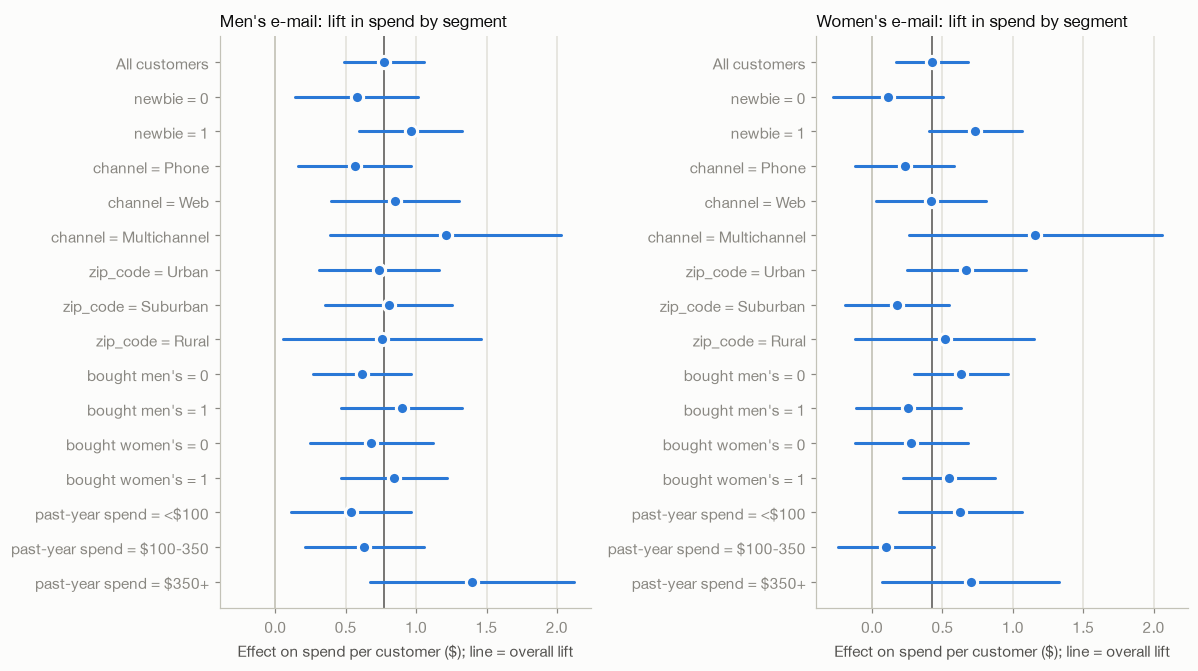

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.2), sharex=True)
seg_defs = [("All customers", None, None), ("newbie", "newbie", [0, 1]), ("channel", "channel", ["Phone", "Web", "Multichannel"]),
            ("zip_code", "zip_code", ["Urban", "Suburban", "Rural"]), ("bought men's", "mens", [0, 1]),
            ("bought women's", "womens", [0, 1]), ("past-year spend", "hist_band", ["<$100", "$100-350", "$350+"])]
for ax, arm in zip(axes, (1, 2)):
    d0 = h[h.arm.isin([0, arm])]; rows = []
    for title, var, levels in seg_defs:
        if var is None:
            sub = [("All customers", d0)]
        else:
            sub = [(f"{title} = {l}", d0[d0[var] == l]) for l in levels]
        for lab, g in sub:
            e = an.diff_in_means(g.spend.to_numpy(), (g.arm == arm).to_numpy().astype(int)); rows.append((lab, e.estimate, e.ci_low, e.ci_high))
    ypos = np.arange(len(rows))[::-1]
    overall = rows[0][1]
    ax.axvline(0, color=AXIS, lw=1); ax.axvline(overall, color=INK2, lw=1)
    for yp, (lab, est, lo, hi) in zip(ypos, rows):
        ax.plot([lo, hi], [yp, yp], color=BLUE, lw=2, solid_capstyle="round")
    ax.plot([r[1] for r in rows], ypos, "o", color=BLUE, ms=8, mec=SURFACE, mew=2)
    ax.set_yticks(ypos, [r[0] for r in rows]); ax.grid(axis="y", visible=False)
    ax.set_title(f"{arm_names[arm]}: lift in spend by segment", loc="left", fontsize=11, color=INK)
    ax.set_xlabel("Effect on spend per customer ($); line = overall lift")
fig.tight_layout(); fig.savefig("../reports/figures/04_segments.png", dpi=160); plt.show()

- Men's e-mail: no sign of heterogeneity (omnibus p ~ 0.58). The lift is positive in every segment and the intervals overlap the overall line.
- Women's e-mail: the omnibus test does reject (p ~ 0.014, ~0.03 even allowing for the two e-mails), so its effect probably varies between customers. The variable that stands out is `newbie`: the lift is much larger for new customers than for existing ones. That variable's own test (raw p ~ 0.018) doesn't survive the Holm correction over 12 exploratory tests though (adjusted p ~ 0.21), so it's a hypothesis for a follow-up experiment rather than a finding.
- It only changes the decision if the Women's e-mail, which is worse on average, beats the Men's one for some group you can identify. The policy analysis below checks exactly that.

(c) Why is there so little power for heterogeneity? Detecting a difference between the lifts of two segments is a four-cell comparison, and its minimum detectable effect is about twice that of a plain A/B test with the same total sample.

In [12]:
n_cell = int(len(h) / 3 / 2)                                   # customers per arm per segment if a segment is half the sample
mde_main = power.mde_mean(sd, n_arm)
mde_inter = power.mde_mean(sd, n_cell) * np.sqrt(2)           # difference of two lift estimates, each from a two-arm contrast
print(f"MDE for the main effect:             ${mde_main:.2f}")
print(f"MDE for a difference between two half-sample segments' lifts: about ${mde_inter:.2f}")
print("Observed 'interest match' differences were ~$0.3, well below that.")

MDE for the main effect:             $0.31
MDE for a difference between two half-sample segments' lifts: about $0.63
Observed 'interest match' differences were ~$0.3, well below that.


(d) Policy learning with three actions. Instead of testing segments one at a time, I learn from the data which action (no e-mail, Men's, Women's) has the highest expected spend for each customer, and then evaluate that policy honestly: per-arm gradient boosting models fitted out-of-fold (5-fold cross-fitting), a doubly robust estimate of each policy's value using the known assignment probability (1/3), and a paired comparison with "Men's e-mail to everyone". Hyperparameters are fixed in advance (shallow, regularized trees).

In [13]:
Xf = dummies.copy(); Xf["log_history"] = np.log(h.history); Xf = Xf.to_numpy(float)
arm, y = h.arm.to_numpy(), h.spend.to_numpy(); probs = np.full(3, 1 / 3)

def run_policy(seed):
    mu = up.cross_fit_arm_means(Xf, arm, y, 3, n_folds=5, seed=seed, depth=2, leaf=500, iters=100)
    learned = mu.argmax(axis=1)
    sc_learned = up.dr_policy_scores(mu, arm, y, learned, probs)
    sc_mens = up.dr_policy_scores(mu, arm, y, np.ones(len(y), int), probs)
    return mu, learned, sc_learned, sc_mens

mu, learned, sc_learned, sc_mens = run_policy(0)
policies = {"No e-mail to anyone": np.zeros(len(y), int), "Women's e-mail to everyone": np.full(len(y), 2),
            "Random e-mail (1/3 each)": np.random.default_rng(0).integers(0, 3, len(y)),
            "Men's e-mail to everyone": np.ones(len(y), int), "Learned policy (cross-fitted)": learned}
rows = []
for name, pol in policies.items():
    v, se = up.dr_policy_value(mu, arm, y, pol, probs)
    rows.append({"policy": name, "value ($ per customer)": v, "± 95%": 1.96 * se, "share none": np.mean(pol == 0), "share men's": np.mean(pol == 1), "share women's": np.mean(pol == 2)})
pol_tab = pd.DataFrame(rows).set_index("policy"); display(pol_tab)

diff = sc_learned - sc_mens
print(f"Learned minus 'Men's to everyone': {diff.mean():+.3f} $/customer  95% CI [{diff.mean() - 1.96 * diff.std(ddof=1) / np.sqrt(len(diff)):+.3f}, {diff.mean() + 1.96 * diff.std(ddof=1) / np.sqrt(len(diff)):+.3f}]")
seeds = [run_policy(s) for s in range(1, 6)]
print("Same comparison with 5 other cross-fitting splits:", [round(float((s[2] - s[3]).mean()), 3) for s in seeds])

,value ($ per customer),± 95%,share none,share men's,share women's
policy,,,,,
No e-mail to anyone,0.6512,0.1554,1.0000,0.0000,0.0000
Women's e-mail to everyone,1.0797,0.2031,0.0000,0.0000,1.0000
Random e-mail (1/3 each),1.1513,0.2125,0.3329,0.3356,0.3315
Men's e-mail to everyone,1.4242,0.2381,0.0000,1.0000,0.0000
Learned policy (cross-fitted),1.3592,0.2288,0.0123,0.8297,0.1580


Learned minus 'Men's to everyone': -0.065 $/customer  95% CI [-0.189, +0.059]


Same comparison with 5 other cross-fitting splits: [-0.154, -0.188, -0.219, -0.022, -0.19]


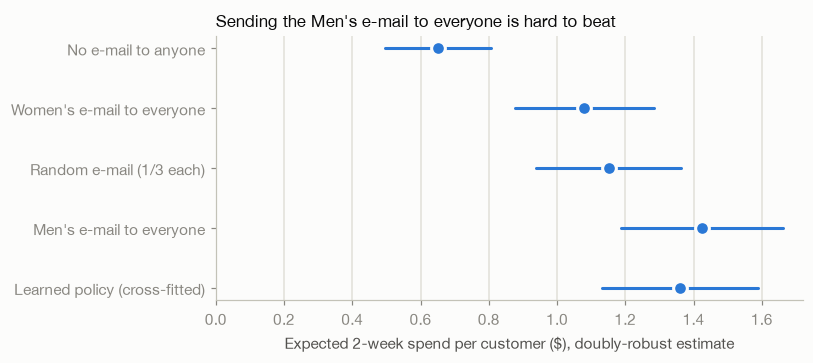

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
r = pol_tab.iloc[::-1]; ypos = np.arange(len(r))
for yp, (_, row) in zip(ypos, r.iterrows()):
    ax.plot([row["value ($ per customer)"] - row["± 95%"], row["value ($ per customer)"] + row["± 95%"]], [yp, yp], color=BLUE, lw=2, solid_capstyle="round")
ax.plot(r["value ($ per customer)"], ypos, "o", color=BLUE, ms=9, mec=SURFACE, mew=2)
ax.set_yticks(ypos, r.index); ax.grid(axis="y", visible=False); ax.set_xlim(0, None)
ax.set_xlabel("Expected 2-week spend per customer ($), doubly-robust estimate")
ax.set_title("Sending the Men's e-mail to everyone is hard to beat", loc="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig("../reports/figures/04_policy_value.png", dpi=160); plt.show()

Every e-mail policy beats sending nothing, and the Men's e-mail is the best fixed policy. The learned policy sends the Men's e-mail to most customers (83%), the Women's to 16% and nothing to about 1%, but its estimated value is no better than "Men's to everyone": the paired difference is -\$0.07 per customer with an interval that includes zero, and on five other cross-fitting splits the point estimate is negative too (between -\$0.02 and -\$0.22). Most likely this is estimation noise: the scores just aren't accurate enough to find the customers for whom the Women's e-mail really wins.

So the data doesn't support anything more complex than "send the Men's e-mail". With a 1% conversion rate there isn't enough signal, which is what the power calculation above already suggested.

## Summary

1. Decision: send the Men's e-mail to all customers (+\$0.77 per customer, CI ~\$0.49-1.05). It beats the Women's e-mail (+\$0.35, p ~ 0.03 after adjustment) and no e-mail, and the break-even cost per e-mail is far above realistic sending costs.
2. No evidence that targeting helps. The interest-match hypotheses aren't significant, no exploratory segment survives the multiplicity correction, and a cross-fitted three-action policy doesn't beat the simple rule. The one hint of real heterogeneity (the Women's e-mail working better for new customers, omnibus p ~ 0.014) is something to test separately. This is a power limit (sd/mean ~14) and doesn't prove that heterogeneity is absent.
3. CUPED doesn't always help: ~0.04% here against ~19% in the simulated app. It's worth measuring the correlation before promising any variance reduction.
4. Visits are precise and revenue is noisy, but a sensitive proxy is only useful once you've shown it tracks the business outcome.
5. Next experiment: a larger or longer test of the Men's e-mail with a revenue holdout, also measuring unsubscribes and repeat purchases after two weeks.

Limitations: the data is from 2008 and covers past-year buyers of a single retailer, the window is two weeks, the outcome is revenue rather than profit, there's no information on e-mail costs, unsubscribes or fatigue, and I assume customers don't affect each other.

Next: the same analysis in SQL (notebook 05).